# LangGraph Basics: Build a Small Message Graph

This notebook builds a simple graph that adds a greeting to a message and then converts the result to uppercase. It introduces the core LangGraph workflow: define state, write nodes, connect the graph, compile it, and invoke it.

By the end, you should be able to explain how state moves through nodes and how a graph definition becomes an executable workflow.

In [1]:
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END

## 1. Define the graph state

A graph's **state** is the structured data that nodes can read and update as the graph runs. Here, a Pydantic model gives the state one field, `message`, and a default empty string. The type tells us what data this workflow expects to carry.

In [2]:
class CurrentState(BaseModel):
    message : str = ""

## 2. Create the graph builder

`StateGraph` uses the state model to define what data flows through the workflow. At this point we are describing the graph; it becomes runnable after it is compiled.

In [3]:
graph = StateGraph(CurrentState)

## 3. Add nodes and connect them

A **node** is a Python function that receives the current state, performs one step, and returns the updated state. This graph has two nodes: `greet` adds a greeting, then `to_upper` capitalizes the whole message.

Edges define the execution order. `START` marks the entry point, `END` marks completion, and the named edges connect the two node functions into a straight-line workflow.

In [4]:
#Nodes are functions which perform an action in the graph
def greet(state:CurrentState):
    state.message = f"Greetings! Your message is {state.message}"
    return state


def to_upper(state:CurrentState):
    state.message = state.message.upper()
    return state


In [5]:
graph.add_node("greet_user", greet)
graph.add_node("convert_msg_to_upper_case", to_upper)

graph.add_edge(START, "greet_user")
graph.add_edge("greet_user", "convert_msg_to_upper_case")
graph.add_edge("convert_msg_to_upper_case", END)

## 4. Compile and run

Compilation turns the graph definition into an executable graph. `invoke` then starts a run with the initial state. The message passes through both nodes in edge order, and the returned value contains the final state.

In [6]:
final_graph = graph.compile()

The input message is intentionally short so it is easy to follow through the two transformations. Expected flow: `I am learning LangGraph!`, then `Greetings! Your message is I am learning LangGraph!`, then `GREETINGS! YOUR MESSAGE IS I AM LEARNING LANGGRAPH!`.

In [7]:
final_graph.invoke({"message": "I am learning LangGraph!"})

{'message': 'GREETINGS! YOUR MESSAGE IS I AM LEARNING LANGGRAPH!'}

## 5. Visualize the workflow

The diagram below is another view of the same graph: it shows the start, the two Python-function nodes, and the end in their execution order.

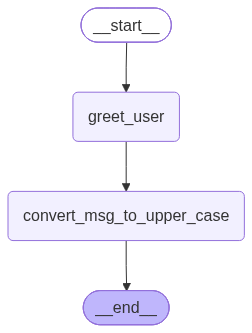

In [8]:
from IPython.display import Image
Image(final_graph.get_graph().draw_mermaid_png())